In [4]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# 1. Load data mentah
raw_data = load_breast_cancer()
df = pd.DataFrame(raw_data.data, columns=raw_data.feature_names)
df['target'] = raw_data.target  # 0: Malignant, 1: Benign

# Tambahkan kolom ID
df.insert(0, 'id', range(1001, 1001 + len(df)))

# 2. Split Tahap 1: 80% Train dan 20% Temp (Val + Test)
train_df, temp_df = train_test_split(
    df, 
    test_size=0.20, 
    random_state=42, 
    stratify=df['target']
)

# 3. Split Tahap 2: Bagi 20% Temp tadi jadi 50%-50% (masing-masing 10% dari total data)
val_df, test_df = train_test_split(
    temp_df, 
    test_size=0.50, 
    random_state=42, 
    stratify=temp_df['target']
)

# 4. Buat test_features (tanpa target) dan sample_submission
test_features = test_df.drop(columns=['target'])
sample_sub = pd.DataFrame({
    'id': test_df['id'],
    'target': 0  # Dummy prediction default
})

# 5. Export ke CSV
train_df.to_csv('train.csv', index=False)
val_df.to_csv('val.csv', index=False)
test_features.to_csv('test.csv', index=False)
sample_sub.to_csv('sample_submission.csv', index=False)

print("✅ Berhasil membuat:")
print(f"- train.csv : {train_df.shape[0]} baris (80%)")
print(f"- val.csv   : {val_df.shape[0]} baris (10%)")
print(f"- test.csv  : {test_features.shape[0]} baris (10%)")

✅ Berhasil membuat:
- train.csv : 455 baris (80%)
- val.csv   : 57 baris (10%)
- test.csv  : 57 baris (10%)


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
train = pd.read_csv('train.csv')
val = pd.read_csv('val.csv')
test = pd.read_csv('test.csv')
sample_sub = pd.read_csv('sample_submission.csv')

# 2. Cek Dimensi Data
print("=== DIMENSI DATASET ===")
print("Train Shape      :", train.shape)
print("Validation Shape :", val.shape)
print("Test Shape       :", test.shape)

# Tampilkan 5 data teratas train
train.head()

=== DIMENSI DATASET ===
Train Shape      : (455, 32)
Validation Shape : (57, 32)
Test Shape       : (57, 31)


,id,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,1547,10.32,16.35,65.31,324.9,0.09434,0.04994,0.01012,0.005495,0.1885,...,21.77,71.12,384.9,0.1285,0.08842,0.04384,0.02381,0.2681,0.07399,1
1,1433,20.18,19.54,133.80,1250.0,0.11330,0.14890,0.21330,0.125900,0.1724,...,25.07,146.00,1479.0,0.1665,0.29420,0.53080,0.21730,0.3032,0.08075,0
2,1175,10.66,15.15,67.49,349.6,0.08792,0.04302,0.00000,0.000000,0.1928,...,19.20,73.20,408.3,0.1076,0.06791,0.00000,0.00000,0.2710,0.06164,1
3,1222,13.56,13.90,88.59,561.3,0.10510,0.11920,0.07860,0.044510,0.1962,...,17.13,101.10,686.6,0.1376,0.26980,0.25770,0.09090,0.3065,0.08177,1
4,1290,11.37,18.89,72.17,396.0,0.08713,0.05008,0.02399,0.021730,0.2013,...,26.14,79.29,459.3,0.1118,0.09708,0.07529,0.06203,0.3267,0.06994,1


Kesimpulan nya yaitu: 

Dataset berhasil dimuat ke dalam memori dengan skema pembagian Train-Validation-Test rasio 80:10:10. Dimana Data Latih (train) terdiri dari 455 baris, Data Validasi (val) terdiri dari 57 baris, dan Data Uji (test) terdiri dari 57 baris. Total keseluruhan sampel adalah 569 data pasien. Terdapat 32 kolom pada data latih (1 kolom id, 30 kolom atribut medis/morfologi sel, dan 1 kolom label target). Kolom target pada data test telah dipisahkan untuk pengujian model.

In [6]:
# 1. Informasi Tipe Data
print("=== INFO DATA TRAIN ===")
train.info()

# 2. Cek Missing Values
print("\n=== MISSING VALUES CHECK ===")
print("Missing values pada Train :", train.isnull().sum().sum())
print("Missing values pada Val   :", val.isnull().sum().sum())
print("Missing values pada Test  :", test.isnull().sum().sum())

# 3. Cek Data Duplikat
print("\n=== DUPLICATE DATA CHECK ===")
print("Data duplikat pada Train :", train.duplicated().sum())
print("Data duplikat pada Val   :", val.duplicated().sum())
print("Data duplikat pada Test  :", test.duplicated().sum())

=== INFO DATA TRAIN ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 455 entries, 0 to 454
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       455 non-null    int64  
 1   mean radius              455 non-null    float64
 2   mean texture             455 non-null    float64
 3   mean perimeter           455 non-null    float64
 4   mean area                455 non-null    float64
 5   mean smoothness          455 non-null    float64
 6   mean compactness         455 non-null    float64
 7   mean concavity           455 non-null    float64
 8   mean concave points      455 non-null    float64
 9   mean symmetry            455 non-null    float64
 10  mean fractal dimension   455 non-null    float64
 11  radius error             455 non-null    float64
 12  texture error            455 non-null    float64
 13  perimeter error          455 non-null    float64
 14  ar

Kesimpulannya :

Seluruh kolom pada dataset berjenis numerik, dimana float64 untuk atribut medis dan int64 untuk id serta target. Disini tidak terdapat variabel kategorikal yang memerlukan proses Encoding. Pada tahap Missing Values, Tidak ditemukan missing values di seluruh file (train, val, maupun test). Dan tahap cek duplikasi data, hasil pengecekan menunjukkan angka 0 pada seluruh subset data, menandakan tidak ada entri pasien yang terduplikasi.

Dapat di katakan, Dataset tergolong sangat bersih (clean dataset), sehingga tidak memerlukan imputasi data maupun drop rows.

In [7]:
# Menampilkan statistik deskriptif 10 fitur pertama
train.describe().T[['mean', 'std', 'min', '50%', 'max']].head(10)

,mean,std,min,50%,max
id,1277.654945,164.998497,1001.00000,1277.00000,1567.0000
mean radius,14.067213,3.499380,6.98100,13.27000,28.1100
mean texture,19.247363,4.405291,9.71000,18.82000,39.2800
mean perimeter,91.557407,24.149231,43.79000,85.98000,188.5000
mean area,648.541099,344.944564,143.50000,541.80000,2499.0000
mean smoothness,0.096167,0.013458,0.06251,0.09566,0.1447
mean compactness,0.103869,0.053522,0.01938,0.09097,0.3454
mean concavity,0.089193,0.081747,0.00000,0.05999,0.4268
mean concave points,0.048344,0.038925,0.00000,0.03263,0.2012
mean symmetry,0.180618,0.028074,0.10600,0.17810,0.3040


Kesimpulannya:

Terdapat variasi skala yang sangat signifikan antar fitur numerik. Sebagai contoh, fitur `mean area` memiliki rentang nilai hingga ribuan (143.5 - 2499.0), sementara fitur seperti `mean smoothness` atau `mean concave points` berada pada rentang desimal yang sangat kecil (0.048 - 0.144).

Implikasinya, tahap Feature Scaling (seperti StandardScaler atau RobustScaler) nantinya wajib dilakukan pada tahap Preprocessing sebelum melakukan pelatihan model Machine Learning agar fitur dengan rentang besar tidak mendominasi model.

C:\Users\user\AppData\Local\Temp\ipykernel_23344\49214345.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='target', data=train, palette=['#e74c3c', '#2ecc71'])


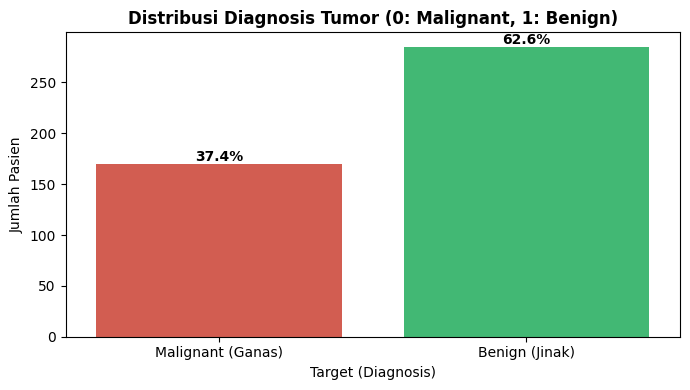

In [8]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(x='target', data=train, palette=['#e74c3c', '#2ecc71'])
plt.title('Distribusi Diagnosis Tumor (0: Malignant, 1: Benign)', fontsize=12, fontweight='bold')
plt.xlabel('Target (Diagnosis)')
plt.ylabel('Jumlah Pasien')
plt.xticks([0, 1], ['Malignant (Ganas)', 'Benign (Jinak)'])

# Menambahkan persentase di atas bar
total = len(train)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Kesimpulannya:

Pada data latih, kelas target didominasi oleh tumor Benign (Jinak) yaitu sebesar 62.6% (285 pasien), sedangkan tumor Malignant (Ganas) sebesar 37.4% (170 pasien). 

Kondisi ini menunjukkan adanya moderate class imbalance. Meskipun tidak terlalu ekstrim, proporsi ini perlu diperhatikan saat memilih metrik evaluasi model (seperti memperhatikan Recall dan F1-Score untuk kelas Malignant).

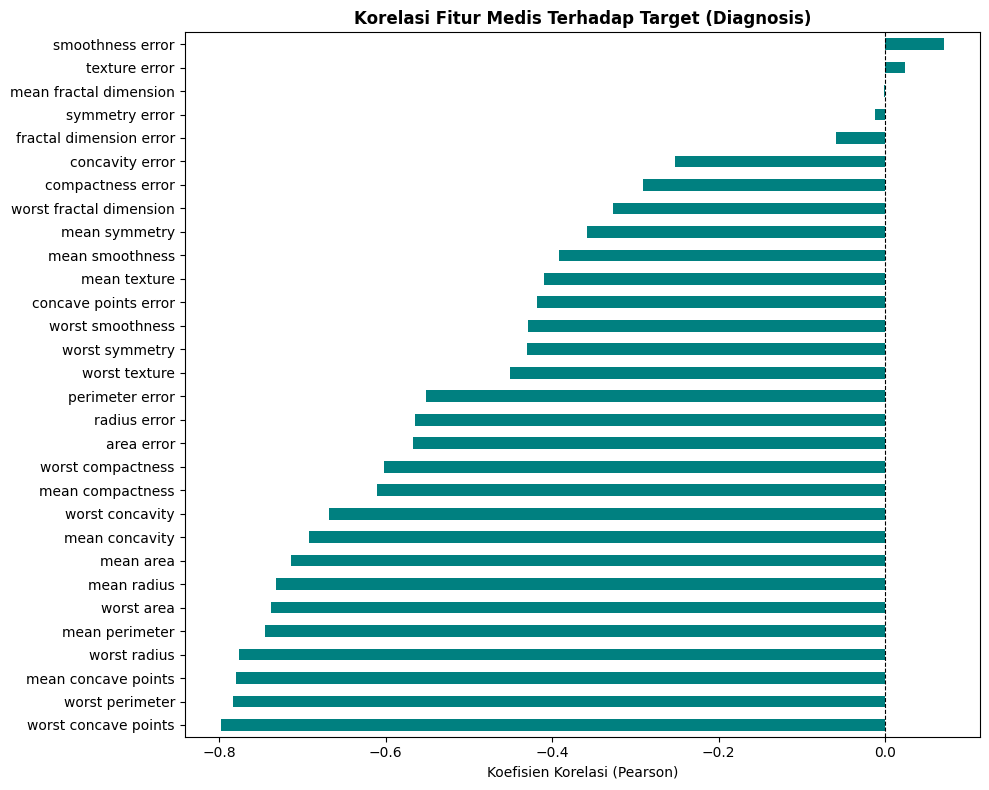

In [9]:
plt.figure(figsize=(10, 8))

# Hitung korelasi semua fitur terhadap target (membuang kolom 'id')
corr_target = train.drop(columns=['id']).corr()['target'].sort_values()

# Visualisasi Top Fitur paling berkorelasi (tanpa target itu sendiri)
corr_target.drop('target').plot(kind='barh', color='teal')
plt.title('Korelasi Fitur Medis Terhadap Target (Diagnosis)', fontsize=12, fontweight='bold')
plt.xlabel('Koefisien Korelasi (Pearson)')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.tight_layout()
plt.show()

Kesimpulannya:

Sebagian besar fitur morfologi sel memiliki nilai korelasi negatif yang cukup kuat terhadap variabel target (0: Malignant, 1: Benign). 

Fitur seperti `worst concave points`, `worst perimeter`, `worst radius`, dan `mean concave points` memiliki korelasi negatif tertinggi (r < -0.7). Hal ini mengindikasikan secara medis bahwa semakin besar ukuran radius, keliling (perimeter), serta tingkat cekungan sel (concave points), semakin besar kecenderungan tumor tersebut bersifat Ganas (Malignant).

C:\Users\user\AppData\Local\Temp\ipykernel_23344\1725394867.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=train, ax=axes[i], palette=['#e74c3c', '#2ecc71'])
C:\Users\user\AppData\Local\Temp\ipykernel_23344\1725394867.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['Malignant (0)', 'Benign (1)'])
C:\Users\user\AppData\Local\Temp\ipykernel_23344\1725394867.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=train, ax=axes[i], palette=['#e74c3c', '#2ecc71'])
C:\Users\user\AppData\Local\Temp\ipykernel_23344\1725394867.py:10: Use

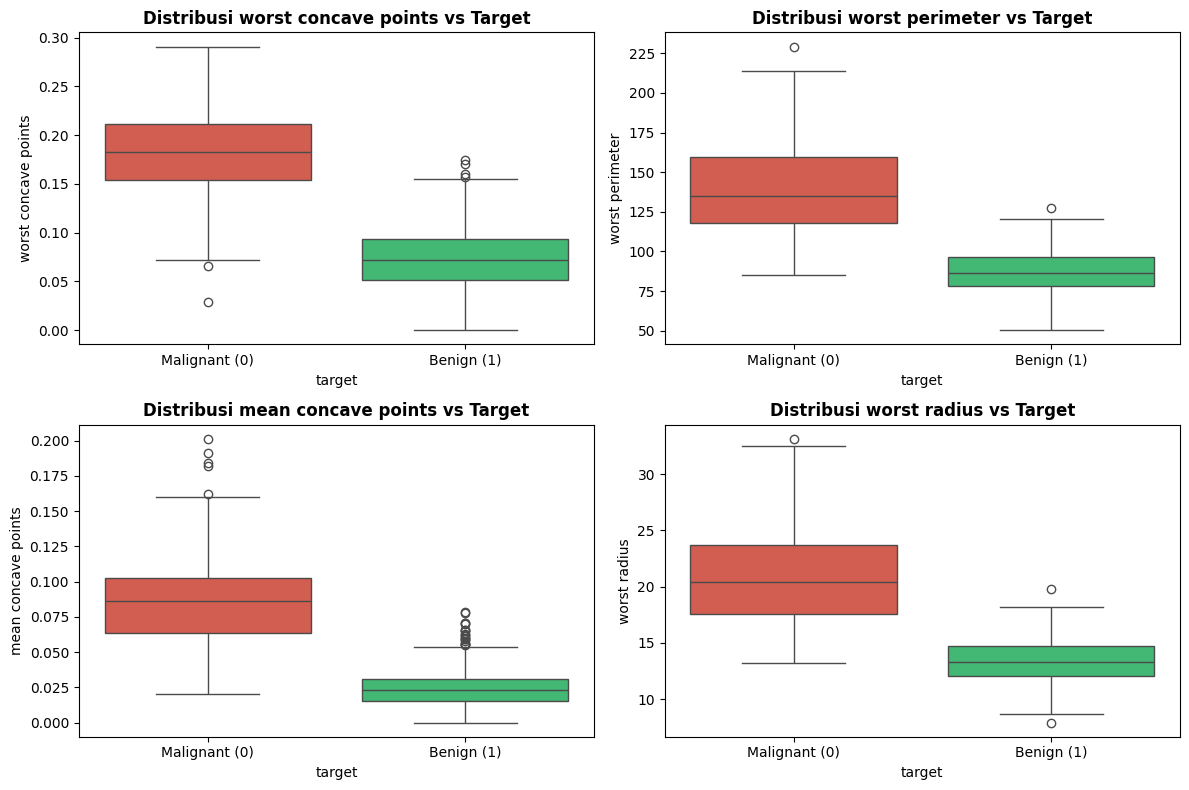

In [10]:
# Ambil 4 fitur dengan korelasi terkuat terhadap target
top_features = corr_target.drop('target').abs().sort_values(ascending=False).head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(top_features):
    sns.boxplot(x='target', y=col, data=train, ax=axes[i], palette=['#e74c3c', '#2ecc71'])
    axes[i].set_title(f'Distribusi {col} vs Target', fontweight='bold')
    axes[i].set_xticklabels(['Malignant (0)', 'Benign (1)'])

plt.tight_layout()
plt.show()

Kesimpulannya:

1. Pemisahan Kelas (Separability): Terlihat perbedaan nilai yang sangat jelas antara kategori Malignant dan Benign pada 4 fitur utama. Pasien dengan diagnosis Malignant secara konsisten memiliki rentang nilai yang lebih tinggi pada ukuran dan struktur sel.
2. Penanganan Outliers: Terdapat beberapa data pencilan (outliers) pada kategori Benign maupun Malignant. Karena data ini merupakan atribut klinis/biologis pasien yang nyata, outliers ini tidak dihapus (do not drop), melainkan dipertahankan agar tidak menghilangkan informasi medis yang valid.